# 02 · Completion signaling on the hot path

CQ data vs flag-in-payload vs sentinel vs remote-write counter vs trailing READ, with per-post instruction counts: what each relies on, and what it costs.

**README sections covered:** [6. How the receiver learns data arrived](../docs/explained/06-completion-signaling.md)

Figures are written to `docs/figures/` (model figures: arithmetic, proofs and repo results) and `docs/figures/<MODE>/` (measured on the machine that ran the notebook).

In [1]:
MODE = "local"            # "local": smoke runs on this machine (tcp / tcp;ofi_rxm / shm providers)
                          # "cluster": this host is the client, the server runs on PEER over ssh
PEER = "server1"         # ssh host for the server side (cluster mode)
PEER_IP = "192.168.1.242" # server address on the RDMA netdev; default taken from benchmark_dual_qp_remote.py, check it
REMOTE_REPO = None        # repo path on PEER if it differs from this host
DOMAIN = "rxe0"           # RDMA device / libfabric domain on both nodes
SV_GID_INDEX = None       # set if the auto-picked GID (first IPv4-mapped) is wrong, e.g. "1"
HOT_CPU = None            # pin the hot loop (cluster: pick a core away from the NIC IRQs)
COLD_CPU = None           # pin the cold stream thread
ITERS = None              # None: 2000 local, 20000 cluster
RESULTS_SUBDIR = "fabric"


In [2]:
import os, sys, json, socket, subprocess, time
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "middleware").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
HOST = socket.gethostname()
STAMP = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
RESULTS = (ROOT / "benchmarks" / "results" / RESULTS_SUBDIR) if MODE == "cluster" else Path("/tmp/scuffed-local") / RESULTS_SUBDIR
RESULTS.mkdir(parents=True, exist_ok=True)
FIGDIR = ROOT / "docs" / "figures"
(FIGDIR / MODE).mkdir(parents=True, exist_ok=True)

import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
    "lines.markersize": 4, "figure.constrained_layout.use": False})
C = {"hot": "#f97316", "cold": "#38bdf8", "spill": "#a78bfa", "ok": "#34d399", "bad": "#f43f5e",
     "gold": "#facc15", "ink": "#1f2937", "muted": "#94a3b8"}

def fig(name, model=False, caption=None, f=None):
    """Save the current figure as PNG + PDF and show it.
    model=True: arithmetic or repo results, same on every machine -> docs/figures/<name>
    model=False: measured on this machine -> docs/figures/<MODE>/<name>"""
    f = f or plt.gcf()
    d = FIGDIR if model else FIGDIR / MODE
    f.tight_layout()
    for ext in ("png", "pdf"):
        f.savefig(d / f"{name}.{ext}", bbox_inches="tight")
    print(f"figure -> {d.relative_to(ROOT)}/{name}.png" + (f"  |  {caption}" if caption else ""))
    plt.show()

def save(name, obj):
    p = RESULTS / f"{HOST}_{name}.json"
    obj = {"host": HOST, "utc": STAMP, "mode": MODE, **obj}
    p.write_text(json.dumps(obj, indent=2, default=str))
    print("wrote", p)
    return p

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, cwd=ROOT)
    print(r.stdout[-4000:], r.stderr[-2000:])
    if check and r.returncode:
        raise RuntimeError(f"{cmd} -> {r.returncode}")
    return r
print("repo:", ROOT, "| host:", HOST, "| mode:", MODE, "| results ->", RESULTS, "| figures ->", FIGDIR)

repo: /home/claude/scuffedrdma | host: vm | mode: local | results -> /tmp/scuffed-local/fabric | figures -> /home/claude/scuffedrdma/docs/figures


## Math: what each completion mechanism relies on

A one-sided RDMA write places bytes in the target's memory without involving the target's CPU, so the target needs some way to learn the bytes are there. Five mechanisms, and the ordering fact each one needs to be correct ([docs/explained/06](../docs/explained/06-completion-signaling.md)):

- **Fact 1 (in-order execution).** Operations posted on one reliable connection (RC queue pair, `FI_EP_MSG` endpoint) are executed by the target in the order they were posted. Guaranteed by the InfiniBand architecture for RC.
- **Fact 2 (completion after placement).** A write-with-immediate generates the target-side completion only after the data has been placed. Guaranteed (`fi_rma(3)`: remote CQ data is reported after the data is available).
- **Not guaranteed:** the order in which the *bytes of one message* become visible in memory. Packets of a multi-packet message may be placed out of order.

| mechanism | initiator posts | target detects by | needs | per-message cost |
|---|---|---|---|---|
| `cq` | `fi_writedata` (WRITE_WITH_IMM) | RX CQ entry with remote CQ data | Fact 2 | one posted receive consumed, one CQ poll |
| `flag` | one write, last 8 B = sequence number | spinning on that word | in-order placement of the last word: holds within one packet, not across packets | none (one cache line read) |
| `sentinel` | payload write, then an 8 B write | spinning on the sentinel | Fact 1 plus write-after-write ordering (`FI_ORDER_WAW`) | a second work request |
| `cntr` | one write | `FI_REMOTE_WRITE` counter | provider must count remote writes (probed; skipped if not) | counter read |
| `read` | write, then an 8 B RDMA read | initiator's read completion | Fact 1: the read is executed after the write, so its response proves placement | a round trip; this is the IBM Storage Scale write flush (`verbsRdmaWriteFlush = rdma-read`) |

The expected ordering of latencies is `flag` < `sentinel` ≈ `cntr` < `cq` < `read`, because each adds one more thing the NIC or the CPU must do per message. Whether that ordering holds, and by how much, is E5. `--perf` adds user-space instructions retired per post (`perf_event_open`), the per-operation overhead metric from Papadopoulou et al. A mechanism is worth adopting only if it moves p99 and is correct on the NIC in use.

In [3]:
from benchmarks.fabric import runner
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
CLUSTER = MODE == "cluster"
N = ITERS or (20000 if CLUSTER else 2000)
W = max(100, N // 20)
PAIR = dict(peer=PEER, peer_ip=PEER_IP, remote_repo=REMOTE_REPO) if CLUSTER else {}
ENV = {"SV_GID_INDEX": str(SV_GID_INDEX)} if SV_GID_INDEX is not None else {}
STACKS = runner.stacks(MODE)
if CLUSTER:
    for st in STACKS:
        if st["tool"] == "sf_bench":
            st["args"] += ["-d", DOMAIN]
        else:
            ENV.setdefault("SV_IB_PORT", "1")
PIN = (["--hot-cpu", str(HOT_CPU)] if HOT_CPU is not None else []) + (["--cold-cpu", str(COLD_CPU)] if COLD_CPU is not None else [])
print(runner.build(remote=PEER if CLUSTER else None, remote_repo=REMOTE_REPO))
for st in STACKS: print(st["label"], st["tool"], st["args"])

{'sf_bench': 'ok', 'sv_bench': 'ok'}
libfabric tcp MSG (local smoke) sf_bench ['-p', 'tcp', '-t', 'msg']
libfabric tcp;ofi_rxm RDM (local smoke) sf_bench ['-p', 'tcp;ofi_rxm', '-t', 'rdm']
libfabric shm RDM (local smoke) sf_bench ['-p', 'shm', '-t', 'rdm']


## Measured: one-way latency per mechanism and payload

In [4]:
MECHS = ["cq", "flag", "sentinel", "cntr", "read"]
SIZES = "8,64,512,4096,16384" if CLUSTER else "64,4096"
raw, rows = [], []
for st in STACKS:
    for m in MECHS:
        d = runner.try_pair(st["tool"], st["args"] + ["-m", "sig", "-M", m, "-n", str(N), "-w", str(W), "-S", SIZES, "--perf"], env=ENV, **PAIR)
        raw.append(d); rows += runner.rows_sig(d, st["label"])
df = pd.DataFrame(rows)
df[[c for c in ["label", "mech", "size", "p50_us", "p99_us", "p999_us", "post_instructions_mean", "metric", "skipped", "error"] if c in df]]

,label,mech,size,p50_us,p99_us,p999_us,metric,skipped
0,libfabric tcp MSG (local smoke),cq,64.0,10.1623,36.1364,156.6788,one_way_us_rtt_over_2,NaN
1,libfabric tcp MSG (local smoke),cq,4096.0,13.1623,37.1606,129.7363,one_way_us_rtt_over_2,NaN
2,libfabric tcp MSG (local smoke),flag,64.0,9.1545,59.4242,228.5664,one_way_us_rtt_over_2,NaN
3,libfabric tcp MSG (local smoke),flag,4096.0,11.9898,32.2811,47.2956,one_way_us_rtt_over_2,NaN
4,libfabric tcp MSG (local smoke),sentinel,64.0,18.2782,50.5667,126.4057,one_way_us_rtt_over_2,NaN
5,libfabric tcp MSG (local smoke),sentinel,4096.0,22.7968,57.8618,125.5345,one_way_us_rtt_over_2,NaN
6,libfabric tcp MSG (local smoke),NaN,NaN,NaN,NaN,NaN,NaN,remote-write counter missing or not incremente...
7,libfabric tcp MSG (local smoke),read,64.0,27.7170,66.4856,109.9172,write_plus_read_completion_us,NaN
8,libfabric tcp MSG (local smoke),read,4096.0,25.2260,96.2887,267.1181,write_plus_read_completion_us,NaN
9,libfabric tcp;ofi_rxm RDM (local smoke),cq,64.0,10.5122,31.0754,57.6309,one_way_us_rtt_over_2,NaN


wrote /tmp/scuffed-local/fabric/vm_completion_signaling.json


figure -> docs/figures/local/06_completion_measured.png  |  E5; local mode is the tcp provider on one host


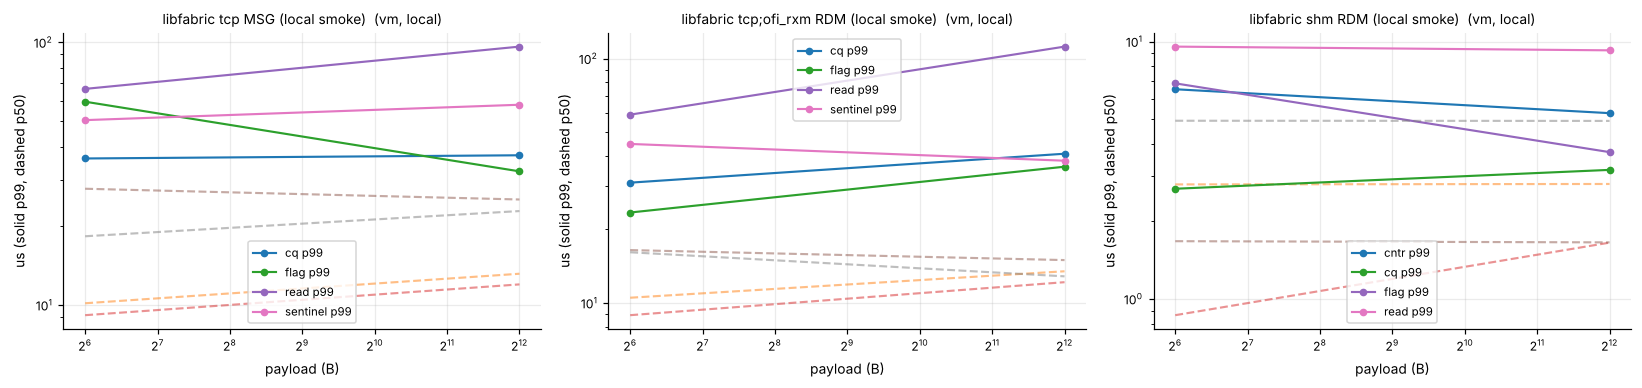

In [5]:
save("completion_signaling", {"rows": rows, "raw": raw})
ok = df.dropna(subset=["p50_us"]) if "p50_us" in df else df
labels = list(dict.fromkeys(ok.label))
figx, axes = plt.subplots(1, len(labels), figsize=(5 * len(labels), 3.6), squeeze=False)
for ax, lab in zip(axes[0], labels):
    for m, g in ok[ok.label == lab].groupby("mech"):
        ax.plot(g["size"], g["p99_us"], marker="o", label=f"{m} p99")
        ax.plot(g["size"], g["p50_us"], ls="--", alpha=.5)
    ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_title(f"{lab}  ({HOST}, {MODE})", fontsize=9)
    ax.set_xlabel("payload (B)"); ax.set_ylabel("us (solid p99, dashed p50)"); ax.legend()
fig("06_completion_measured", caption="E5; local mode is the tcp provider on one host")

In [6]:
# instructions retired per post, when perf counters are available
if "post_instructions_mean" in ok and ok["post_instructions_mean"].notna().any():
    piv = ok.pivot_table(index="mech", columns="label", values="post_instructions_mean")
    print(piv.round(0))
    figp, ax = plt.subplots(figsize=(5.5, 3))
    piv.plot.bar(ax=ax); ax.set_ylabel("instructions / post (mean)"); ax.set_title("per-operation overhead by mechanism")
    fig("06_completion_instructions")
else:
    print("no perf counters on this host (perf_event_open unavailable); instructions/post skipped")

no perf counters on this host (perf_event_open unavailable); instructions/post skipped
